## Rigid Boby Motion

*   Moving an Object
*   Moving a Camera in the World Frame
*   Converting coordinates from Camera Frame to World Frame
*   Moving a Camera in its own frame



In [1]:
# @title
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
from math import sin, cos, pi

Auxiliary Functions

In [2]:
# @title
def set_plot(ax=None,figure = None,lim=[-2,2]):
    if figure ==None:
        figure = plt.figure(figsize=(8,8))
    if ax==None:
        ax = plt.axes(projection='3d')
    ax.set_xlim(lim)
    ax.set_xlabel("x axis")
    ax.set_ylim(lim)
    ax.set_ylabel("y axis")
    ax.set_zlim(lim)
    ax.set_zlabel("z axis")
    return ax

#adding quivers to the plot
def draw_arrows(point,base,axis,length=1.5):
    # The object base is a matrix, where each column represents the vector
    # of one of the axis, written in homogeneous coordinates (ax,ay,az,0)


    # Plot vector of x-axis
    axis.quiver(point[0],point[1],point[2],base[0,0],base[1,0],base[2,0],color='red',pivot='tail',  length=length)
    # Plot vector of y-axis
    axis.quiver(point[0],point[1],point[2],base[0,1],base[1,1],base[2,1],color='green',pivot='tail',  length=length)
    # Plot vector of z-axis
    axis.quiver(point[0],point[1],point[2],base[0,2],base[1,2],base[2,2],color='blue',pivot='tail',  length=length)

    return axis


### Setting printing options
np.set_printoptions(formatter={'float': lambda x: "{0:0.3f}".format(x)})
np.set_printoptions(precision=3,suppress=True)



Create your functions to translate and rotate objects in the world frame.

In [3]:
# @title
# Write down your code

def move (dx, dy, dz, obj=None): # se eu não especificar o objeto, vai retornar só a matriz
  # criando a matriz de translação
  translation = np.eye(4)
  translation[0,-1] = dx
  translation[1,-1] = dy
  translation[2,-1] = dz
  # transladando o objeto
  obj = translation@obj
  # retorna a matriz e o objeto
  if obj is None: return translation
  else:           return translation, obj

def x_rotation(angle, obj=None):
  angle = angle*pi/180
  # criando a matriz de rotação
  rotation = np.eye(4)
  rotation[1,0:3] = [0, cos(angle), -sin(angle)]
  rotation[2,0:3] = [0, sin(angle),  cos(angle)]
  # rotacionando o objeto
  obj = rotation@obj
  # retorna matriz e objeto
  if obj is None: return rotation
  else:           return rotation, obj

def y_rotation(angle, obj=None):
  angle = angle*pi/180
  # criando a matriz de rotação
  rotation = np.eye(4)
  rotation[0,0:3] = [ cos(angle), 0, sin(angle)]
  rotation[2,0:3] = [-sin(angle), 0, cos(angle)]
  # rotacionando o objeto
  obj = rotation@obj
  # retorna matriz e objeto
  if obj is None: return rotation
  else:           return rotation, obj

def z_rotation(angle, obj=None):
  angle = angle*pi/180
  # criando a matriz de rotação
  rotation = np.eye(4)
  rotation[0,0:3] = [cos(angle), -sin(angle), 0]
  rotation[1,0:3] = [sin(angle),  cos(angle), 0]
  # rotacionando o objeto
  obj = rotation@obj
  # retorna matriz e objeto
  if obj is None: return rotation
  else:           return rotation, obj

Consider a camera frame represented by the axes below. Note that the Z-axis, which represents the camera’s optical axis, is pointing upward.

In [4]:
# @title
# base vector values
e1   = np.array([[1],[0],[0],[0]]) # X
e2   = np.array([[0],[1],[0],[0]]) # Y
e3   = np.array([[0],[0],[1],[0]]) # Z
base = np.hstack((e1,e2,e3))

print ('Cartesian base: \n',base)
#origin point
origin = np.array([[0],[0],[0],[1]])

cam   = np.hstack((base,origin))
world = np.hstack([base,origin])

print ('Origin: \n',origin)
print ('cam: \n',cam)


Cartesian base: 
 [[1 0 0]
 [0 1 0]
 [0 0 1]
 [0 0 0]]
Origin: 
 [[0]
 [0]
 [0]
 [1]]
cam: 
 [[1 0 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]]


Text(0.5, 0.92, 'Camera and World Reference Frames')

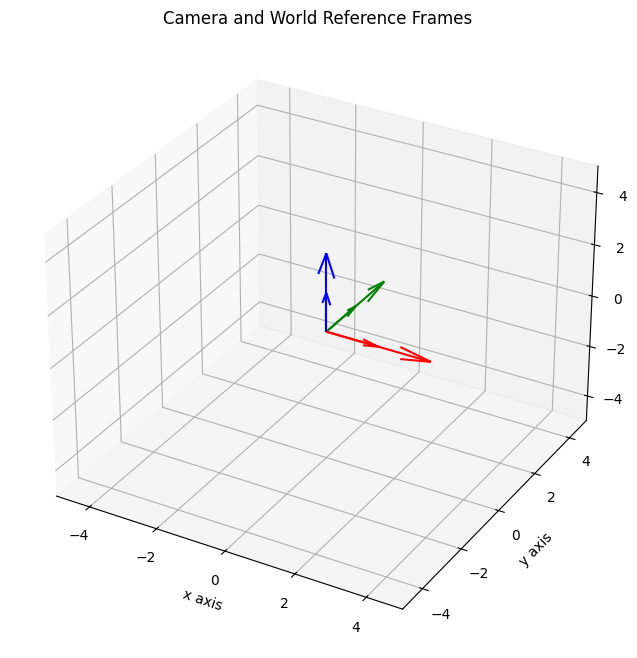

In [5]:
# @title
# Ploting the world reference frame and the camera frame
axis = set_plot(lim=[-5,5])
axis = draw_arrows(world[:,-1],world[:,0:3],axis,3)
axis = draw_arrows(cam[:,-1],cam[:,0:3],axis,1.5)
axis.set_title("Camera and World Reference Frames")

Perform the necessary transformations so that the camera’s optical axis (along the Z-axis) is placed horizontally, with the Y-axis pointing downward and the X-axis pointing to the right (X-axis current orientation unchanged).
After that, perform one rotation more aroud the world Z-axis of -70 degrees.
Then, move the rotated camera to the point (4,4,3).

Write down your code.

In [19]:
# @title
# Write your code for moving the camera.

# Primeira rotação
R1, cam01 = x_rotation(-90, cam)
# Segunda rotação
R2, cam01 = z_rotation(-70, cam01)
# Translação
T, cam01 = move(4, 4, 3, cam01)
M = T@R2@R1

Plot the world and camera frames.

Text(0.5, 0.92, 'Camera and World Reference Frames')

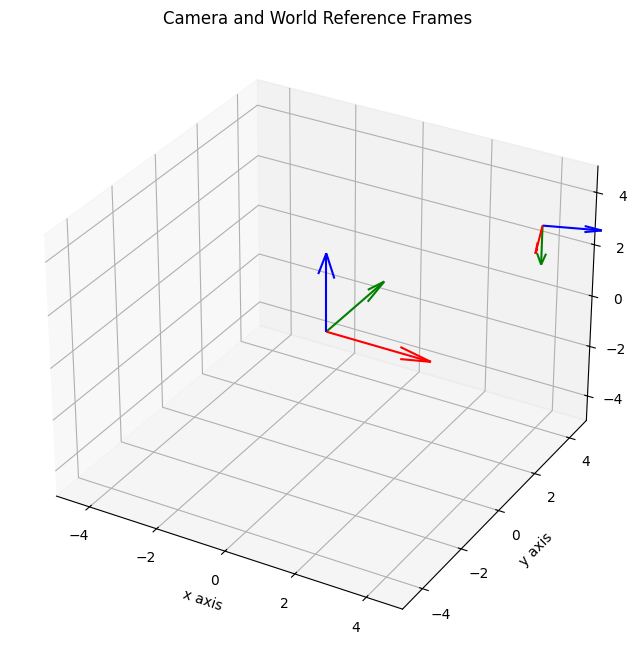

In [20]:
# @title
# Ploting the world reference frame and the camera frame
axis = set_plot(lim=[-5,5])
axis = draw_arrows(world[:,-1],world[:,0:3],axis,3)
axis = draw_arrows(cam01[:,-1],cam01[:,0:3],axis,1.5)
axis.set_title("Camera and World Reference Frames")

Now let's include a house in the scene.

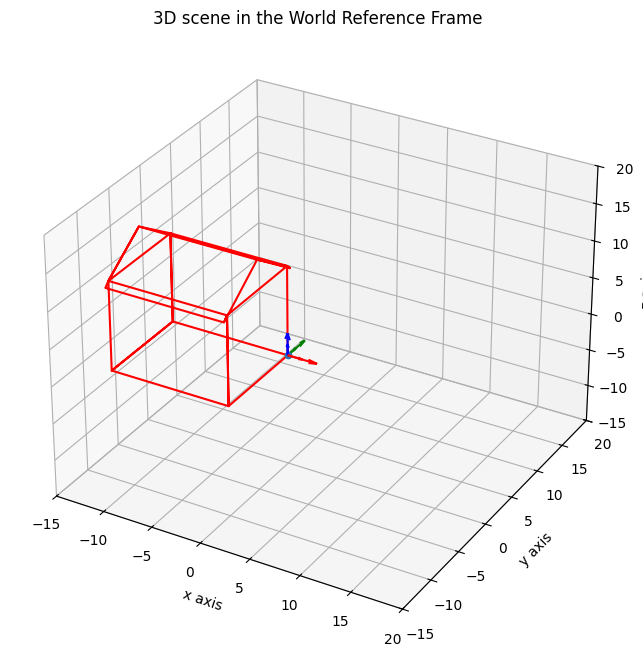

In [8]:
# @title
#Creating a house

house = np.array([[       0,         0,         0],
                  [       0,  -10.0000,         0],
                  [       0, -10.0000,    12.0000],
                  [       0,  -10.4000,   11.5000],
                  [       0,   -5.0000,   16.0000],
                  [       0,         0,   12.0000],
                  [       0,    0.5000,   11.4000],
                  [       0,         0,   12.0000],
                  [       0,         0,         0],
                  [-12.0000,         0,         0],
                  [-12.0000,   -5.0000,         0],
                  [-12.0000,  -10.0000,         0],
                  [       0,  -10.0000,         0],
                  [       0,  -10.0000,   12.0000],
                  [-12.0000,  -10.0000,   12.0000],
                  [-12.0000,         0,   12.0000],
                  [       0,         0,   12.0000],
                  [       0,  -10.0000,   12.0000],
                  [       0,  -10.5000,   11.4000],
                  [-12.0000,  -10.5000,   11.4000],
                  [-12.0000,  -10.0000,   12.0000],
                  [-12.0000,   -5.0000,   16.0000],
                  [       0,   -5.0000,   16.0000],
                  [       0,    0.5000,   11.4000],
                  [-12.0000,    0.5000,   11.4000],
                  [-12.0000,         0,   12.0000],
                  [-12.0000,   -5.0000,   16.0000],
                  [-12.0000,  -10.0000,   12.0000],
                  [-12.0000,  -10.0000,         0],
                  [-12.0000,   -5.0000,         0],
                  [-12.0000,         0,         0],
                  [-12.0000,         0,   12.0000],
                  [-12.0000,         0,         0]])

house = np.transpose(house)

#add a vector of ones to the house matrix to represent the house in homogeneous coordinates
house = np.vstack([house, np.ones(np.size(house,1))])

# Plotting the house and camera in the same figure

axis = set_plot(lim=[-15,20])
axis.set_title('3D scene in the World Reference Frame')
draw_arrows(world[:,-1],world[:,0:3],axis,3)
draw_arrows(cam[:,-1],cam[:,0:3],axis,1.5)
axis.plot3D(house[0,:], house[1,:], house[2,:], 'red')

# Plotting the house corner as a reference
axis.scatter(house[0,0], house[1,0], house[2,0],'b')

Now you should rotate the house by -190 degrees around the Z-axis and position it so that its corner (0,0,0) will be at (10, 15, 2).

Quina inicial: 
 [0. 0. 0. 1.]
Quina depois da rotação: 
 [0. 0. 0. 1.]
Distancia entre o ponto final e o inicial: 
 [10. 15.  2.  0.]
Coordenadas da quina na nova posição da casa: 
 [10. 15.  2.  1.]


<Axes3D: title={'center': '3D scene in the World Reference Frame'}, xlabel='x axis', ylabel='y axis', zlabel='z axis'>

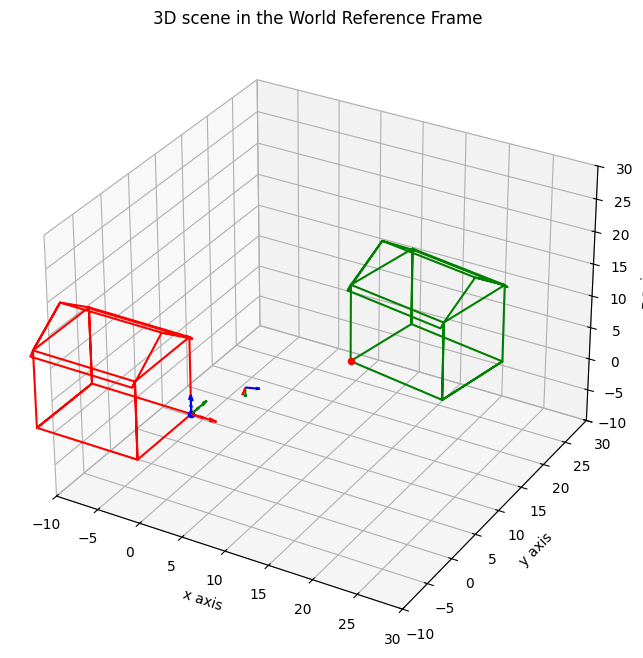

In [9]:
# Write your code below
corner = house[0:4,0]
corner = np.hstack((corner))
print('Quina inicial: \n', corner)
_, house_rotated = z_rotation(-190, house)
print('Quina depois da rotação: \n', house_rotated[0:4,0])
dist = np.array([10, 15, 2, 1]) - house_rotated[0:4,0]
print('Distancia entre o ponto final e o inicial: \n', dist)
_, house_rot_t = move(dist[0], dist[1], dist[2], house_rotated)
print('Coordenadas da quina na nova posição da casa: \n', house_rot_t[0:4,0])


# Plot the house and camera in the same figure
axis = set_plot(lim=[-10,30])
axis.set_title('3D scene in the World Reference Frame')
axis.plot3D(      house[0,:],       house[1,:],       house[2,:], 'red')
axis.plot3D(house_rot_t[0,:], house_rot_t[1,:], house_rot_t[2,:], 'green')
# Plotting the house corner
axis.scatter(      house[0,0],       house[1,0],       house[2,0], c='b')
axis.scatter(house_rot_t[0,0], house_rot_t[1,0], house_rot_t[2,0], c='r')
# Plotting the camera and world reference frames
draw_arrows(world[:,-1], world[:,0:3], axis,   3)
draw_arrows(  cam[:,-1],   cam[:,0:3], axis, 1.5) # camera original
draw_arrows(cam01[:,-1], cam01[:,0:3],  axis,1.5) # camera com transformações

Create your functions to convert from the camera frame to the world frame and vice-versa.

In [10]:
# @title
#Convert from camera frame to world frame
def cam2world (M,point_cam):
      p_world = np.dot(M,point_cam)
      return p_world

#Convert from world frame to camera frame
def world2cam (M,point_world):
      M_inv = np.linalg.inv(M)
      p_cam = np.dot(M_inv,point_world)
      return p_cam

Convert the house corner (first point of the objected marked as a blue point) represented in the world frame to the camera frame.

In [11]:
# @title
# Write your code below and display the result using print.
house_cam01 = world2cam(M, corner)
print('Coordenada da quina casa inicial do ponto de vista da câmera transforamda: \n', house_cam01)

Coordenada da quina casa inicial do ponto de vista da câmera transforamda: 
 [ 2.391  3.    -5.127  1.   ]


Now move the camera (0,0,5) in the world frame.
Please plot the new position of the camera to see if the transformatiob was applied correctly.

Finally, convert again the coordinates of the house corner from the world frame to the camera frame.

Do these new coordinates in the camera frame make any sense?

Coordenada da quina da casa inicial do ponto de vista da cam01: 
 [ 2.391  3.    -5.127  1.   ]
Coordenada da quina da casa inicial do ponto de vista da cam02: 
 [ 2.391  8.    -5.127  1.   ]


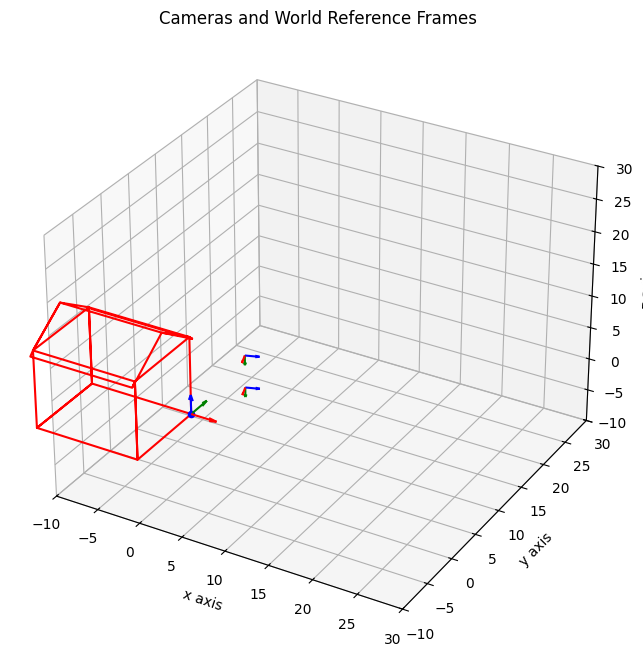

In [12]:
# Write your code below, plot the result and also print the coordinates in both frames to compare.
N, cam02 = move(0,0,5, cam01)

axis = set_plot(lim=[-10,30])

axis.plot3D (      house[0,:],       house[1,:],       house[2,:], 'red')
axis.scatter(      house[0,0],       house[1,0],       house[2,0], c='b')

axis = draw_arrows(world[:,-1],world[:,0:3],axis,3)
axis = draw_arrows(cam01[:,-1],cam01[:,0:3],axis,1.5)
axis = draw_arrows(cam02[:,-1],cam02[:,0:3],axis,1.5)
axis.set_title("Cameras and World Reference Frames")

house_cam01 = world2cam(M, corner)
house_cam02 = world2cam(N@M, corner)
print('Coordenada da quina da casa inicial do ponto de vista da cam01: \n', house_cam01)
print('Coordenada da quina da casa inicial do ponto de vista da cam02: \n', house_cam02)
#   Como o Y tá apontando pra baixo, ele equivale a eixo Z do mundo e tem sentido de crescimento
# para baixo. Então quanto mais pra baixo a quina da casa está, maior o valor de y.
#   Como eu subi a câmera em 5 pontos pelo referêncial do mundo, a cam02 enxerga isso como
# tivéssemos "subido a casa" em 5 pontos. Portanto, entre a a cam01 e a cam02, a coordenada
# da quina da casa pela cam02 recebeu um aumento de 5 pontos

Now write your functions to transform the camera in its own reference frame.

In [13]:
# @title
# Write your code here

def own_move(dx,dy,dz,cam=None):

    c0 = np.eye(4)

    T = np.eye(4)
    T[0,-1]=dx
    T[1,-1]=dy
    T[2,-1]=dz

    cam = cam@T@c0
    if cam is None: return T
    else:           return T, cam

def own_z_rotation(angle, cam):
    angle = angle*pi/180
    c0 = np.eye(4)
    rotation_matrix=np.array([[cos(angle),-sin(angle),  0, 0],
                              [sin(angle), cos(angle),  0, 0],
                              [         0,          0,  1, 0],
                              [         0,          0,  0, 1]])
    cam = cam@rotation_matrix@c0
    if cam is None: return rotation_matrix
    else:           return rotation_matrix, cam

def own_x_rotation(angle, cam):
    angle = angle*pi/180
    c0 = np.eye(4)
    rotation_matrix=np.array([[1,          0,           0, 0],
                              [0, cos(angle), -sin(angle), 0],
                              [0, sin(angle),  cos(angle), 0],
                              [0,          0,           0, 1],])
    cam = cam@rotation_matrix@c0
    if cam is None: return rotation_matrix
    else:           return rotation_matrix, cam

def own_y_rotation(angle, cam):
    angle = angle*pi/180
    c0 = np.eye(4)
    rotation_matrix=np.array([[ cos(angle), 0, sin(angle), 0],
                              [          0, 1,          0, 0],
                              [-sin(angle), 0, cos(angle), 0],
                              [          0, 0,          0, 1],])
    cam = cam@rotation_matrix@c0
    if cam is None: return rotation_matrix
    else:           return rotation_matrix, cam

Imagine now that you need to rotate your camera within its own reference frame. First, the camera should rotate by 20 degrees around its Y-axis and then rotate by −15 degrees around its X-axis, creating a slight tilt. In the end, the camera should remain in the same position (coordinates) where it was before, but rotated and tilted. Write your code below.

Important tip: Perform one rotation at a time and plot the result after each step to make sure it is correct.

<Axes3D: title={'center': '3D scene in the World Reference Frame'}, xlabel='x axis', ylabel='y axis', zlabel='z axis'>

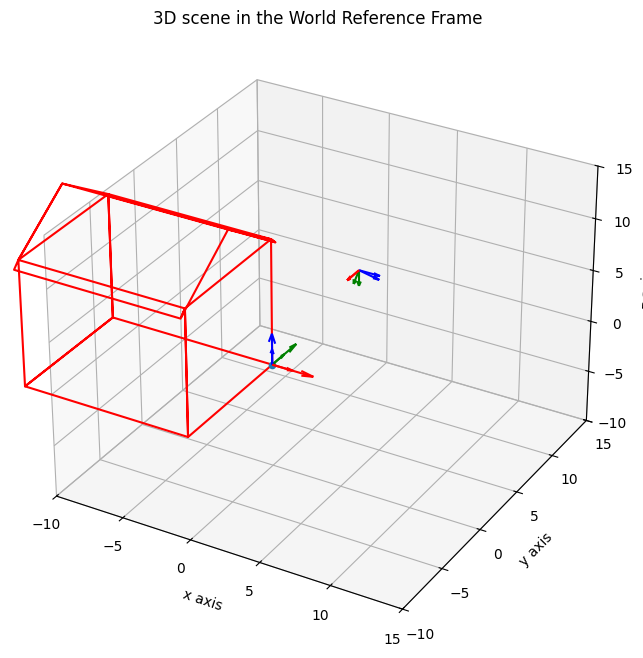

In [14]:
# Plot the house and initial camera in the same figure

axis = set_plot(lim=[-10,15])
axis.set_title('3D scene in the World Reference Frame')
axis.plot3D(house[0,:], house[1,:], house[2,:], 'red')
# Plotting the house corner
axis.scatter(house[0,0], house[1,0], house[2,0],'b')
# Plotting the camera and world reference frames
draw_arrows(world[:,-1],world[:,0:3],axis,3)
draw_arrows(cam[:,-1],cam[:,0:3],axis,1.5)

# Write down your code
a1, cam03 = own_y_rotation(20, cam02)
draw_arrows(cam03[:,-1],cam03[:,0:3],axis,1.5)
a2, cam04 = own_x_rotation(-15, cam03)
draw_arrows(cam04[:,-1],cam04[:,0:3],axis,1.5)

Now, let's lift the camera 10 units within its own reference frame along the y-axis.
Plot the result.

Finally, let's move the camera, within its own reference frame, away from the house by 7 units along the z-axis and 3 units to the right along the x-axis.

Plot again the result.

<Axes3D: title={'center': '3D scene in the World Reference Frame'}, xlabel='x axis', ylabel='y axis', zlabel='z axis'>

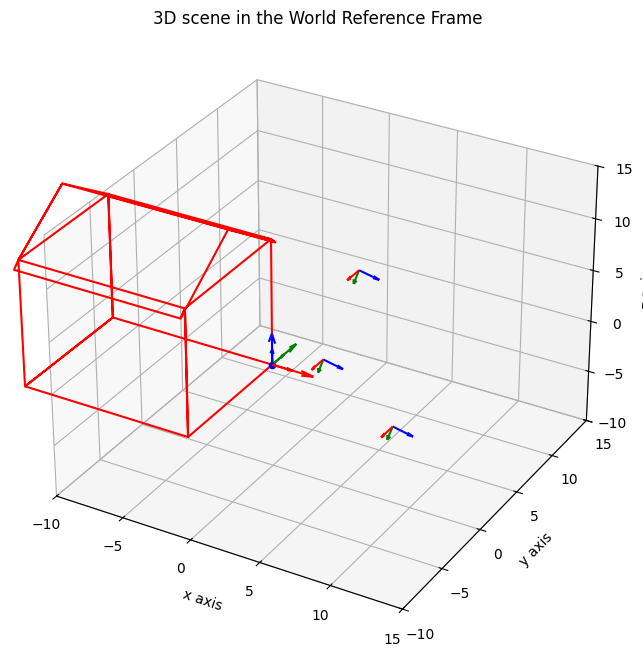

In [15]:
# Plot the house and initial camera in the same figure

axis = set_plot(lim=[-10,15])
axis.set_title('3D scene in the World Reference Frame')
axis.plot3D(house[0,:], house[1,:], house[2,:], 'red')
# Plotting the house corner
axis.scatter(house[0,0], house[1,0], house[2,0], c='b')
# Plotting the camera and world reference frames
draw_arrows(world[:,-1],world[:,0:3],axis,3)
draw_arrows(cam[:,-1],cam[:,0:3],axis,1.5)


# Write down your code

draw_arrows(cam04[:,-1],cam04[:,0:3],axis,1.5) # pra relembrar a posição da última câmera
a3, cam05 = own_move(0,10,0, cam04)
draw_arrows(cam05[:,-1],cam05[:,0:3],axis,1.5)
a4, cam06 = own_move(3, 0, 7, cam05)
draw_arrows(cam06[:,-1],cam06[:,0:3],axis,1.5) # supostamente era pra ter andado para a direita, mas foi pra baixo...(???)

Convert again the coordinates of the house corner from the world frame to the camera frame.

In [16]:
# Write your code below and display the result using print to show and compare the coordinates in both frames.

corner = house[0:3,0]
corner = np.hstack((corner, [1]))

O = N @ M @ a1 @ a2 @ a3 @a4

ponto_cam6 = world2cam(O, corner)

print("As cordenadas da quina da casa no ponto da cam6 é: \n", ponto_cam6)

As cordenadas da quina da casa no ponto da cam6 é: 
 [ 1.    -1.237 -8.793  1.   ]
